1. Clone GitHub Repository

In [16]:
!git clone https://github.com/natsumisugimoto817/sakura_analytics.git
%cd sakura_analytics
!pip install -q -r requirements.txt

Cloning into 'sakura_analytics'...
remote: Enumerating objects: 624, done.
remote: Counting objects: 100% (398/398), done.
remote: Compressing objects: 100% (300/300), done.
remote: Total 624 (delta 146), reused 322 (delta 92), pack-reused 226 (from 1)
Receiving objects: 100% (624/624), 122.08 MiB | 15.17 MiB/s, done.
Resolving deltas: 100% (147/147), done.
Updating files: 100% (340/340), done.
/content/sakura_analytics/sakura_analytics


2. Load Datasets

In [17]:
import sys
sys.path.append("src")

from model_data import load_features, feature_columns, TARGET

for date in ["feb1", "mar1", "mar15"]:
    df = load_features(date, source="csv")
    print(date, df.shape)

feb1 (4365, 33)
mar1 (4365, 36)
mar15 (4365, 49)


3. Explore Datasets

In [18]:
df = load_features("mar15", source="csv")
df.head()

,station_id,location,prefecture,region,latitude,longitude,elevation_m,bloom_year,relocations_before_season,tmean_oct,...,sunshine_mar1_14_missing_days,cum_tmax_feb1_mar14,full_bloom_date,full_bloom_doy,split,fold1,fold2,fold3,fold4,fold5
0,412,Sapporo,Hokkaido,Hokkaido,43.060000,141.328333,17.4,1964,0,10.57,...,1.0,-21.8,1964-05-07,128,development,train,train,train,train,train
1,423,Muroran,Hokkaido,Hokkaido,42.311667,140.975000,39.9,1964,0,12.19,...,0.0,0.7,1964-05-12,133,development,train,train,train,train,train
2,428,Esashi,Hokkaido,Hokkaido,41.866667,140.123333,3.7,1964,0,12.58,...,0.0,80.9,1964-05-08,129,development,train,train,train,train,train
3,430,Hakodate,Hokkaido,Hokkaido,41.816667,140.753333,35.0,1964,0,11.24,...,0.0,29.8,1964-05-10,131,development,train,train,train,train,train
4,433,Kutchan,Hokkaido,Hokkaido,42.900000,140.756667,176.1,1964,0,8.48,...,0.0,-53.8,1964-05-13,134,development,train,train,train,train,train


In [19]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (4365, 49)
Number of rows: 4365
Number of columns: 49


In [20]:
print(df.columns.tolist())

['station_id', 'location', 'prefecture', 'region', 'latitude', 'longitude', 'elevation_m', 'bloom_year', 'relocations_before_season', 'tmean_oct', 'tmean_nov', 'tmean_dec', 'tmean_jan', 'tmean_feb', 'tmax_jan', 'tmin_jan', 'tmax_feb', 'tmin_feb', 'chill_days_0_7c_nov_feb', 'tmin_lowest_nov_feb', 'frost_days_jan_feb', 'gdd5_feb', 'cum_tmax_feb', 'cum_tmean_feb', 'precip_feb_mm', 'precip_feb_missing_days', 'sunshine_feb_h', 'sunshine_feb_missing_days', 'tmean_mar1_14', 'tmax_mar1_14', 'tmin_mar1_14', 'gdd5_mar1_14', 'cum_tmax_mar1_14', 'cum_tmean_mar1_14', 'chill_days_0_7c_mar1_14', 'frost_days_mar1_14', 'precip_mar1_14_mm', 'precip_mar1_14_missing_days', 'sunshine_mar1_14_h', 'sunshine_mar1_14_missing_days', 'cum_tmax_feb1_mar14', 'full_bloom_date', 'full_bloom_doy', 'split', 'fold1', 'fold2', 'fold3', 'fold4', 'fold5']


In [21]:
features = feature_columns(df)

X = df[features]
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4365, 36)
y shape: (4365,)


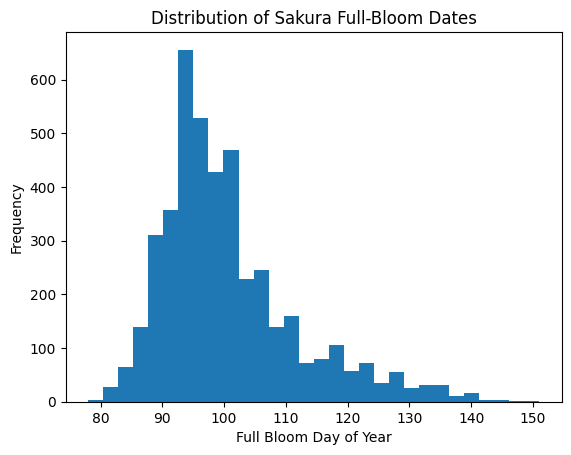

In [22]:
import matplotlib.pyplot as plt

plt.hist(y, bins=30)

plt.xlabel("Full Bloom Day of Year")
plt.ylabel("Frequency")
plt.title("Distribution of Sakura Full-Bloom Dates")

plt.show()

4. Evaluate 30-year Climatology Baseline

In [23]:
sys.path.insert(0, "src/models")

from svr import climatology_30yr
from model_data import load_features, cv_report

# Define the missing variables
forecast_dates = ["feb1", "mar1", "mar15"]
datasets = {date: load_features(date, source="csv") for date in forecast_dates}

for date in forecast_dates:
    df = datasets[date]

    baseline = cv_report(df, climatology_30yr)

    print(f"\n{date.upper()} Baseline:")
    print(baseline.round(3).to_string(index=False))


FEB1 Baseline:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.737 3.514 0.909        0.635
   2 127 3.383 4.393 0.776        0.535
   3 106 3.618 4.505 0.833        0.500
   4  98 3.232 3.774 0.851        0.469
   5  96 6.049 6.679 0.727        0.146
mean 575 3.804 4.573 0.819        0.457

MAR1 Baseline:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.737 3.514 0.909        0.635
   2 127 3.383 4.393 0.776        0.535
   3 106 3.618 4.505 0.833        0.500
   4  98 3.232 3.774 0.851        0.469
   5  96 6.049 6.679 0.727        0.146
mean 575 3.804 4.573 0.819        0.457

MAR15 Baseline:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.737 3.514 0.909        0.635
   2 127 3.383 4.393 0.776        0.535
   3 106 3.618 4.505 0.833        0.500
   4  98 3.232 3.774 0.851        0.469
   5  96 6.049 6.679 0.727        0.146
mean 575 3.804 4.573 0.819        0.457


5. Train the Initial Gradient Boosting Model

In [24]:
from sklearn.ensemble import GradientBoostingRegressor

from model_data import (
    TARGET,
    feature_columns,
    cv_report
)

def predict_gb(train, valid):

    features = feature_columns(train)

    model = GradientBoostingRegressor(
        random_state=42
    )

    model.fit(
        train[features],
        train[TARGET]
    )

    predictions = model.predict(
        valid[features]
    )

    return predictions

6. Evaluate Gradient Boosting Across Three Dates

In [25]:
gb_results = {}

for date in forecast_dates:

    df = datasets[date]

    results = cv_report(df, predict_gb)

    gb_results[date] = results

    print(f"\n{date.upper()} Gradient Boosting:")
    print(results.round(3).to_string(index=False))


FEB1 Gradient Boosting:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 3.026 3.993 0.882        0.635
   2 127 3.901 4.923 0.719        0.457
   3 106 3.714 4.780 0.812        0.500
   4  98 2.395 2.780 0.919        0.653
   5  96 6.608 7.272 0.677        0.115
mean 575 3.929 4.749 0.802        0.472

MAR1 Gradient Boosting:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.115 2.880 0.939        0.709
   2 127 4.371 5.457 0.654        0.378
   3 106 2.898 3.874 0.877        0.642
   4  98 3.169 3.889 0.841        0.500
   5  96 6.656 7.216 0.682        0.094
mean 575 3.842 4.663 0.799        0.465

MAR15 Gradient Boosting:
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.293 3.029 0.932        0.716
   2 127 3.034 4.135 0.802        0.606
   3 106 2.669 3.544 0.897        0.679
   4  98 2.519 2.959 0.908        0.673
   5  96 4.754 5.386 0.823        0.260
mean 575 3.054 3.811 0.872        0.587


7. Hyperparameter Tuning

In [26]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

combinations = list(ParameterGrid(param_grid))

print("Number of combinations:", len(combinations))

for params in combinations:
    print(params)

Number of combinations: 8
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


In [27]:
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from model_data import cv_report, feature_columns, TARGET

tuning_results = {}
best_params = {}

for date in forecast_dates:

    df = datasets[date]
    features = feature_columns(df)

    scores = []

    print(f"\nTuning Gradient Boosting for {date}...")

    for params in combinations:

        def predict_tuned(train, valid):

            model = GradientBoostingRegressor(
                **params,
                random_state=42
            )

            model.fit(
                train[features],
                train[TARGET]
            )

            return model.predict(valid[features])

        report = cv_report(df, predict_tuned)

        mean_mae = report.iloc[-1]["MAE"]

        scores.append({
            **params,
            "MAE": mean_mae
        })

    results_df = pd.DataFrame(scores)

    results_df = results_df.sort_values("MAE")

    tuning_results[date] = results_df

    best_params[date] = {
        key: results_df.iloc[0][key]
        for key in param_grid
    }

    print(f"\nBest results for {date}:")
    print(results_df.head().to_string(index=False))


Tuning Gradient Boosting for feb1...

Best results for feb1:
 learning_rate  max_depth  n_estimators      MAE
          0.05          2           200 3.846115
          0.10          2           100 3.854753
          0.10          2           200 3.869697
          0.05          3           200 3.906939
          0.05          3           100 3.910965

Tuning Gradient Boosting for mar1...

Best results for mar1:
 learning_rate  max_depth  n_estimators      MAE
          0.10          2           200 3.798949
          0.10          3           100 3.841848
          0.10          2           100 3.843339
          0.05          2           200 3.844164
          0.05          3           200 3.852932

Tuning Gradient Boosting for mar15...

Best results for mar15:
 learning_rate  max_depth  n_estimators      MAE
          0.10          3           100 3.053652
          0.05          3           200 3.067798
          0.10          3           200 3.077887
          0.10          2   

In [28]:
from pathlib import Path
import pandas as pd

output_dir = Path("results/gradient_boosting")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save individual tuning results
for date in forecast_dates:
    tuning_results[date].to_csv(
        output_dir / f"gb_{date}_tuning.csv",
        index=False
    )

# 2. Build the comparison DataFrame
comparison_rows = []
for date in forecast_dates:
    default_mae = gb_results[date].iloc[-1]["MAE"]
    tuned_mae = tuning_results[date].iloc[0]["MAE"]
    comparison_rows.append({
        "forecast_date": date,
        "default_mae": default_mae,
        "tuned_mae": tuned_mae,
        "improvement": default_mae - tuned_mae
    })

comparison_df = pd.DataFrame(comparison_rows)

# 3. Save the comparison DataFrame
comparison_df.to_csv(
    output_dir / "gb_default_vs_tuned.csv",
    index=False
)

print("Results saved successfully. Comparison summary:")
print(comparison_df.to_string(index=False))

Results saved successfully. Comparison summary:
forecast_date  default_mae  tuned_mae  improvement
         feb1     3.928590   3.846115     0.082476
         mar1     3.841848   3.798949     0.042900
        mar15     3.053652   3.053652     0.000000


8. Train Gradient Boosting with Anomaly Target

In [30]:
import sys

sys.path.insert(0, "/content/sakura_analytics/src")
sys.path.insert(0, "/content/sakura_analytics/src/models")

from svr import station_reference

print("Import successful!")

Import successful!


In [31]:
from sklearn.ensemble import GradientBoostingRegressor
from model_data import TARGET, feature_columns, cv_report

def predict_gb_anomaly(train, valid):

    # 1. Select input features
    features = feature_columns(train)

    # 2. Calculate the 30-year station reference
    reference_fn = station_reference(
        train,
        ref_years=30,
        min_history=10
    )

    train_reference = reference_fn(train)
    valid_reference = reference_fn(valid)

    # 3. Calculate the anomaly target
    y_anomaly = train[TARGET].to_numpy() - train_reference

    # 4. Create and train Gradient Boosting
    model = GradientBoostingRegressor(
        random_state=42
    )

    model.fit(train[features], y_anomaly)

    # 5. Predict anomalies
    predicted_anomaly = model.predict(valid[features])

    # 6. Convert predictions back to full-bloom DOY
    predicted_doy = valid_reference + predicted_anomaly

    return predicted_doy

In [32]:
import sys
from pathlib import Path

# Locate the project
project_root = Path("/content/sakura_analytics")

# Add project folders to Python's search path
sys.path.insert(0, str(project_root / "src"))
sys.path.insert(0, str(project_root / "src/models"))

# Import machine learning model
from sklearn.ensemble import GradientBoostingRegressor

# Import shared project functions
from model_data import (
    load_features,
    feature_columns,
    cv_report,
    TARGET
)

# Import 30-year station reference
from svr import station_reference

print("All imports successful!")

All imports successful!


In [33]:
anomaly_results = {}

for date in ["feb1", "mar1", "mar15"]:

    df = load_features(date, source="csv")

    report = cv_report(df, predict_gb_anomaly)

    anomaly_results[date] = report

    print(f"\n{date.upper()} — Anomaly Gradient Boosting")
    print(report.round(3).to_string(index=False))


FEB1 — Anomaly Gradient Boosting
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.834 3.682 0.900        0.642
   2 127 3.845 4.889 0.723        0.472
   3 106 3.870 4.791 0.811        0.462
   4  98 2.309 2.855 0.915        0.653
   5  96 6.761 7.320 0.672        0.083
mean 575 3.924 4.707 0.804        0.463

MAR1 — Anomaly Gradient Boosting
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.191 2.792 0.942        0.750
   2 127 4.083 5.397 0.662        0.433
   3 106 2.830 3.699 0.888        0.604
   4  98 2.921 3.485 0.873        0.571
   5  96 6.401 6.894 0.709        0.083
mean 575 3.685 4.453 0.815        0.488

MAR15 — Anomaly Gradient Boosting
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.138 2.747 0.944        0.723
   2 127 3.102 4.200 0.795        0.583
   3 106 2.656 3.510 0.899        0.642
   4  98 2.396 2.926 0.910        0.704
   5  96 4.898 5.352 0.825        0.198
mean 575 3.038 3.747 0.875        0.570


9. Tune the Anomaly Boosting Model

In [34]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}

combinations = list(ParameterGrid(param_grid))

print("Total combinations:", len(combinations))

Total combinations: 8


In [35]:
def predict_gb_anomaly(train, valid, params=None):

    features = feature_columns(train)

    reference_fn = station_reference(
        train,
        ref_years=30,
        min_history=10
    )

    train_ref = reference_fn(train)
    valid_ref = reference_fn(valid)

    y_anomaly = train[TARGET].to_numpy() - train_ref

    model = GradientBoostingRegressor(
        **(params or {}),
        random_state=42
    )

    model.fit(train[features], y_anomaly)

    predicted_anomaly = model.predict(valid[features])

    return valid_ref + predicted_anomaly

In [36]:
import pandas as pd

anomaly_tuning_results = {}

for date in forecast_dates:

    df = load_features(date, source="csv")

    scores = []

    print(f"\nTuning Anomaly Gradient Boosting for {date}...")

    for params in combinations:

        def predict(train, valid):
            return predict_gb_anomaly(train, valid, params)

        report = cv_report(df, predict)

        mean_mae = report.iloc[-1]["MAE"]

        scores.append({
            **params,
            "MAE": mean_mae
        })

    results_df = pd.DataFrame(scores)

    results_df = results_df.sort_values("MAE")

    anomaly_tuning_results[date] = results_df

    print(f"\nBest results for {date}:")
    print(results_df.head().to_string(index=False))


Tuning Anomaly Gradient Boosting for feb1...

Best results for feb1:
 learning_rate  max_depth  n_estimators      MAE
          0.10          2           100 3.782777
          0.05          2           200 3.783012
          0.05          2           100 3.783611
          0.05          3           100 3.841237
          0.10          2           200 3.849730

Tuning Anomaly Gradient Boosting for mar1...

Best results for mar1:
 learning_rate  max_depth  n_estimators      MAE
          0.05          3           100 3.643629
          0.05          2           200 3.652829
          0.10          2           100 3.658461
          0.05          2           100 3.682949
          0.10          3           100 3.685010

Tuning Anomaly Gradient Boosting for mar15...

Best results for mar15:
 learning_rate  max_depth  n_estimators      MAE
          0.10          2           200 3.033838
          0.10          3           100 3.037803
          0.10          3           200 3.040014
    

10. Evaluate the Best Anomaly Models

In [37]:
best_anomaly_results = {}
best_anomaly_params = {}

for date in forecast_dates:

    df = load_features(date, source="csv")

    # Select the best parameters
    best_row = anomaly_tuning_results[date].iloc[0]

    params = {
        "learning_rate": float(best_row["learning_rate"]),
        "max_depth": int(best_row["max_depth"]),
        "n_estimators": int(best_row["n_estimators"])
    }

    best_anomaly_params[date] = params

    # Predict using the best parameters
    def predict_best(train, valid):
        return predict_gb_anomaly(train, valid, params)

    # Evaluate on the same CV folds
    report = cv_report(df, predict_best)

    best_anomaly_results[date] = report

    print(f"\n{date.upper()} — Best Anomaly GB")
    print("Parameters:", params)
    print(report.round(3).to_string(index=False))


FEB1 — Best Anomaly GB
Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.571 3.330 0.918        0.682
   2 127 3.709 4.739 0.739        0.472
   3 106 3.835 4.769 0.813        0.462
   4  98 2.213 2.731 0.922        0.694
   5  96 6.585 7.133 0.689        0.052
mean 575 3.783 4.540 0.816        0.473

MAR1 — Best Anomaly GB
Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.162 2.775 0.943        0.736
   2 127 4.010 5.214 0.685        0.465
   3 106 2.954 3.814 0.880        0.604
   4  98 2.686 3.224 0.891        0.643
   5  96 6.406 6.881 0.710        0.073
mean 575 3.644 4.381 0.822        0.504

MAR15 — Best Anomaly GB
Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}
fold   n   MAE  RMSE    R2  hit_rate_3d
   1 148 2.148 2.741 0.945        0.709
   2 127 3.026 4.165 0.799        0.622
   3 106 2.631 3.419 0.904    

11. Compare Final Candidate Models

In [38]:
summary_rows = []

for date in forecast_dates:

    result = best_anomaly_results[date].iloc[-1]

    summary_rows.append({
        "Forecast Date": date,
        "MAE": result["MAE"],
        "RMSE": result["RMSE"],
        "R2": result["R2"],
        "Hit Rate ±3d": result["hit_rate_3d"]
    })

summary_df = pd.DataFrame(summary_rows)

display(summary_df.round(3))

,Forecast Date,MAE,RMSE,R2,Hit Rate ±3d
0,feb1,3.783,4.540,0.816,0.473
1,mar1,3.644,4.381,0.822,0.504
2,mar15,3.034,3.738,0.875,0.575


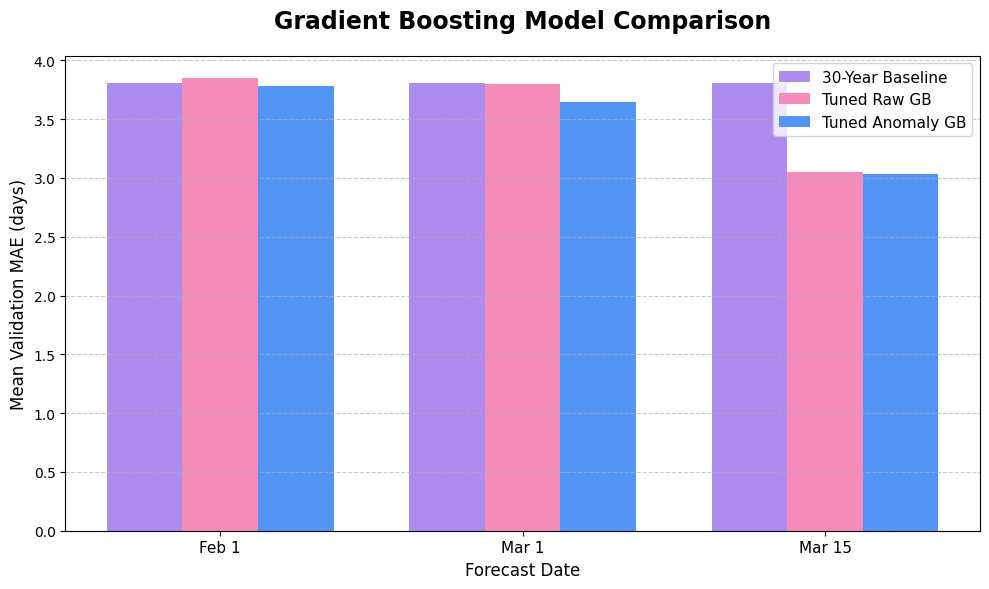

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Create output directory
output_dir = Path("results/gradient_boosting")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Prepare comparison data
comparison_data = pd.DataFrame({
    "Forecast Date": ["Feb 1", "Mar 1", "Mar 15"],

    "30-Year Baseline": [
        3.804, 3.804, 3.804
    ],

    "Tuned Raw GB": [
        tuning_results[d].iloc[0]["MAE"]
        for d in forecast_dates
    ],

    "Tuned Anomaly GB": [
        anomaly_tuning_results[d].iloc[0]["MAE"]
        for d in forecast_dates
    ]
})

# 3. Set bar positions
x = np.arange(len(comparison_data))
width = 0.25

# 4. Create figure
fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width,
    comparison_data["30-Year Baseline"],
    width,
    label="30-Year Baseline",
    color="#AD8BEF"
)

bars2 = ax.bar(
    x,
    comparison_data["Tuned Raw GB"],
    width,
    label="Tuned Raw GB",
    color="#F48BB8"
)

bars3 = ax.bar(
    x + width,
    comparison_data["Tuned Anomaly GB"],
    width,
    label="Tuned Anomaly GB",
    color="#5295F5"
)

# 5. Add title and axis labels
ax.set_title(
    "Gradient Boosting Model Comparison",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Forecast Date", fontsize=12)
ax.set_ylabel("Mean Validation MAE (days)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(comparison_data["Forecast Date"], fontsize=11)

# 6. Customize design elements
ax.legend(fontsize=11, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

# 7. Save and display figure
plt.tight_layout()
plt.savefig(output_dir / "gb_model_comparison.png", dpi=300)
plt.show()

12. Save Model Results

In [42]:
from pathlib import Path

# 1. Create output directory
output_dir = Path("results/gradient_boosting")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Save results for each forecast date
for date in forecast_dates:

    # Best anomaly model CV results
    best_anomaly_results[date].to_csv(
        output_dir / f"gb_anomaly_{date}_cv.csv",
        index=False
    )

    # Anomaly hyperparameter tuning results
    anomaly_tuning_results[date].to_csv(
        output_dir / f"gb_anomaly_{date}_tuning.csv",
        index=False
    )

    # Raw DOY hyperparameter tuning results
    tuning_results[date].to_csv(
        output_dir / f"gb_raw_{date}_tuning.csv",
        index=False
    )

# 3. Save summary table
summary_df.to_csv(
    output_dir / "gb_anomaly_summary.csv",
    index=False
)

# 4. Save model comparison table
comparison_data.to_csv(
    output_dir / "gb_model_comparison.csv",
    index=False
)

# 5. Confirm saved files
print("All files saved successfully!\n")

for file in sorted(output_dir.iterdir()):
    print(file.name)

All files saved successfully!

gb_anomaly_feb1_cv.csv
gb_anomaly_feb1_tuning.csv
gb_anomaly_mar15_cv.csv
gb_anomaly_mar15_tuning.csv
gb_anomaly_mar1_cv.csv
gb_anomaly_mar1_tuning.csv
gb_anomaly_summary.csv
gb_model_comparison.csv
gb_model_comparison.png
gb_raw_feb1_tuning.csv
gb_raw_mar15_tuning.csv
gb_raw_mar1_tuning.csv


13. Feature Importance Analysis

In [43]:
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

from model_data import (
    load_features,
    feature_columns,
    TARGET
)

from svr import station_reference

# 1. Load March 15 dataset
df = load_features("mar15", source="csv")

# 2. Select development data only
train_df = df[df["split"] == "development"].copy()

# 3. Select input features
features = feature_columns(train_df)

# 4. Calculate 30-year station reference
reference_fn = station_reference(
    train_df,
    ref_years=30,
    min_history=10
)

train_ref = reference_fn(train_df)

# 5. Create anomaly target
y_anomaly = train_df[TARGET].to_numpy() - train_ref

# 6. Use the best March 15 hyperparameters
params = {
    "learning_rate": 0.10,
    "max_depth": 2,
    "n_estimators": 200,
    "random_state": 42
}

# 7. Train Gradient Boosting
model = GradientBoostingRegressor(**params)

model.fit(train_df[features], y_anomaly)

print("Model trained successfully!")

Model trained successfully!


In [44]:
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

,Feature,Importance
0,latitude,0.1366
26,gdd5_mar1_14,0.1303
27,cum_tmax_mar1_14,0.1081
5,tmean_nov,0.0834
6,tmean_dec,0.0791
24,tmax_mar1_14,0.0718
21,sunshine_feb_h,0.0585
4,tmean_oct,0.0552
12,tmin_feb,0.0434
15,frost_days_jan_feb,0.0292


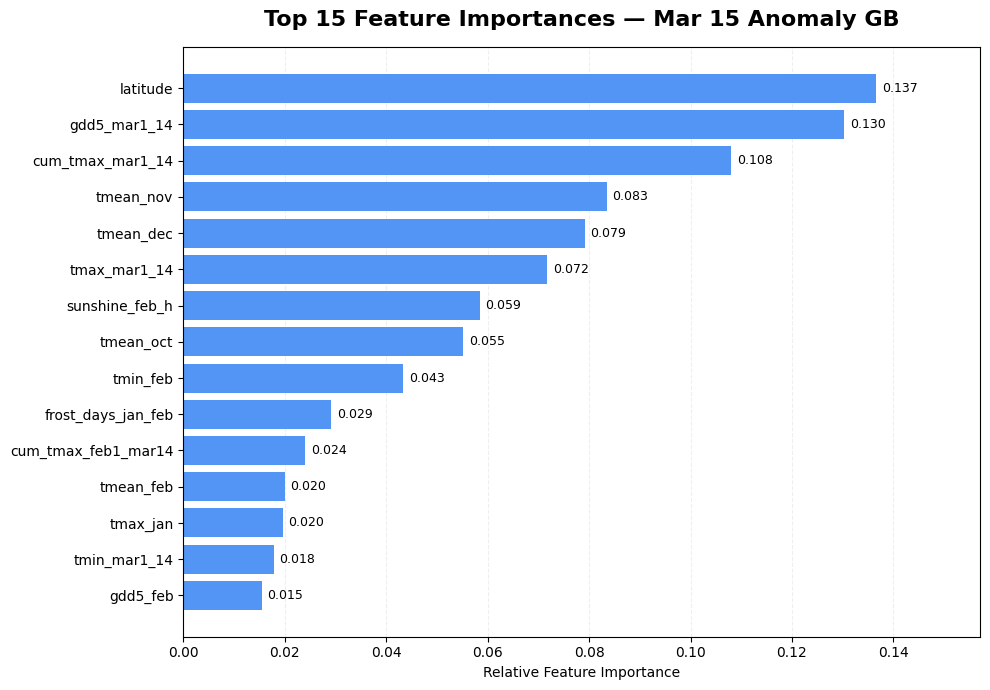

In [45]:
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Create output folder
output_dir = Path("results/gradient_boosting")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Select top 15 features
top_features = importance_df.head(15).sort_values("Importance")

# 3. Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="#5295F5"
)

# 4. Add labels
ax.set_title(
    "Top 15 Feature Importances — Mar 15 Anomaly GB",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Relative Feature Importance")
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

# 5. Add values
ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4,
    fontsize=9
)

ax.set_xlim(0, top_features["Importance"].max() * 1.15)

plt.tight_layout()

# 6. Save figure
plt.savefig(
    output_dir / "gb_mar15_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
importance_df.to_csv(
    output_dir / "gb_mar15_feature_importance.csv",
    index=False
)

print("Feature importance results saved!")

Feature importance results saved!


14. Error Analysis

In [47]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from model_data import load_features, feature_columns, cv_folds, TARGET
from svr import station_reference

# Load March 15 data
df = load_features("mar15", source="csv")

# Select Fold 5
fold5 = [
    (train, valid)
    for k, train, valid in cv_folds(df)
    if k == 5
]

train, valid = fold5[0]

# Select features
features = feature_columns(train)

# Build reference using training data only
reference_fn = station_reference(
    train,
    ref_years=30,
    min_history=10
)

train_ref = reference_fn(train)
valid_ref = reference_fn(valid)

# Create anomaly target
y_anomaly = train[TARGET].to_numpy() - train_ref

# Best March 15 anomaly parameters
model = GradientBoostingRegressor(
    learning_rate=0.10,
    max_depth=2,
    n_estimators=200,
    random_state=42
)

# Train and predict
model.fit(train[features], y_anomaly)

predicted_anomaly = model.predict(valid[features])
predicted_doy = valid_ref + predicted_anomaly

# Create prediction table
fold5_predictions = valid[
    ["station_id", "location", "region", "bloom_year", TARGET]
].copy()

fold5_predictions["predicted_doy"] = predicted_doy

fold5_predictions["error"] = (
    fold5_predictions["predicted_doy"]
    - fold5_predictions[TARGET]
)

fold5_predictions["absolute_error"] = (
    fold5_predictions["error"].abs()
)

display(fold5_predictions.head())

,station_id,location,region,bloom_year,full_bloom_doy,predicted_doy,error,absolute_error
3741,412,Sapporo,Hokkaido,2013,137,128.470897,-8.529103,8.529103
3742,423,Muroran,Hokkaido,2013,141,133.063203,-7.936797,7.936797
3743,430,Hakodate,Hokkaido,2013,132,126.847696,-5.152304,5.152304
3744,575,Aomori,Tohoku,2013,126,121.470119,-4.529881,4.529881
3745,582,Akita,Tohoku,2013,119,114.640073,-4.359927,4.359927


In [48]:
year_analysis = fold5_predictions.groupby("bloom_year").agg(
    n=("absolute_error", "count"),
    MAE=("absolute_error", "mean"),
    Mean_Error=("error", "mean"),
    Max_Error=("absolute_error", "max")
).reset_index()

display(year_analysis.round(3))

,bloom_year,n,MAE,Mean_Error,Max_Error
0,2013,48,4.046,2.533,8.529
1,2014,48,5.882,5.882,11.349


In [49]:
worst_stations = fold5_predictions.sort_values(
    "absolute_error",
    ascending=False
).head(15)

display(worst_stations)

,station_id,location,region,bloom_year,full_bloom_doy,predicted_doy,error,absolute_error
3790,423,Muroran,Hokkaido,2014,125,136.348576,11.348576,11.348576
3796,590,Sendai,Tohoku,2014,101,111.857550,10.857550,10.857550
3791,430,Hakodate,Hokkaido,2014,121,130.964376,9.964376,9.964376
3792,575,Aomori,Tohoku,2014,115,124.849111,9.849111,9.849111
3805,626,Kumagaya,Kanto,2014,91,99.725588,8.725588,8.725588
3789,412,Sapporo,Hokkaido,2014,121,129.704670,8.704670,8.704670
3806,629,Mito,Kanto,2014,92,100.684875,8.684875,8.684875
3741,412,Sapporo,Hokkaido,2013,137,128.470897,-8.529103,8.529103
3827,813,Saga,Kyushu,2014,85,93.237428,8.237428,8.237428
3742,423,Muroran,Hokkaido,2013,141,133.063203,-7.936797,7.936797


15. Residual Analysis

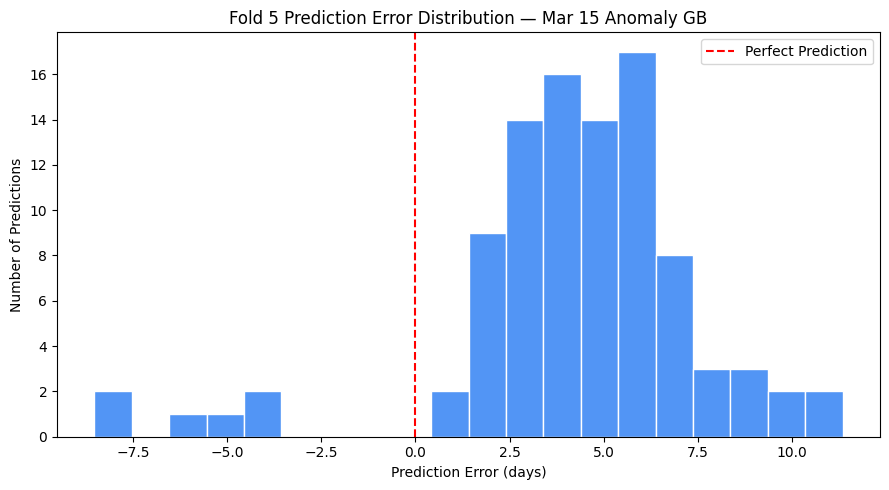

In [50]:
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("results/gradient_boosting")
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    fold5_predictions["error"],
    bins=20,
    color="#5295F5",
    edgecolor="white"
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

ax.set_title("Fold 5 Prediction Error Distribution — Mar 15 Anomaly GB")
ax.set_xlabel("Prediction Error (days)")
ax.set_ylabel("Number of Predictions")
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "gb_fold5_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

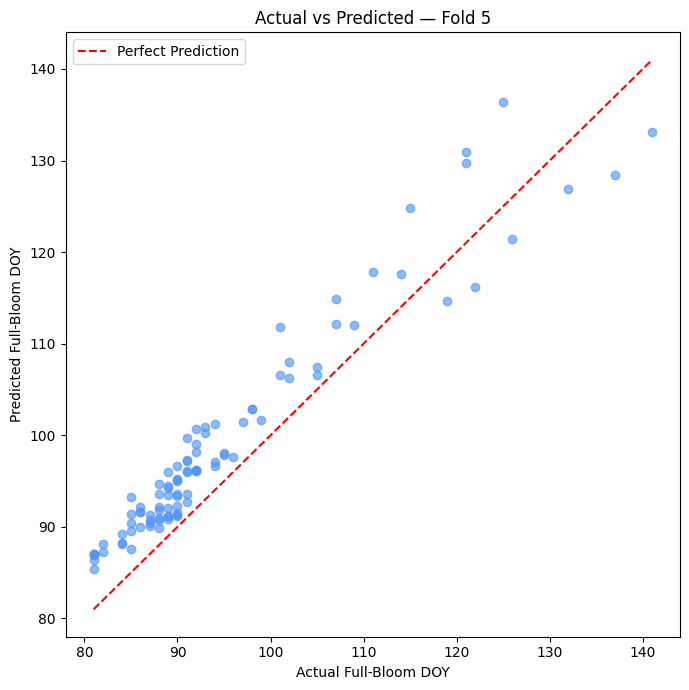

In [51]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    fold5_predictions[TARGET],
    fold5_predictions["predicted_doy"],
    alpha=0.65,
    color="#5295F5"
)

low = min(
    fold5_predictions[TARGET].min(),
    fold5_predictions["predicted_doy"].min()
)

high = max(
    fold5_predictions[TARGET].max(),
    fold5_predictions["predicted_doy"].max()
)

ax.plot(
    [low, high],
    [low, high],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

ax.set_xlabel("Actual Full-Bloom DOY")
ax.set_ylabel("Predicted Full-Bloom DOY")
ax.set_title("Actual vs Predicted — Fold 5")
ax.legend()

plt.tight_layout()

plt.savefig(
    output_dir / "gb_fold5_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

16. Compare Feature Importance Across Forecast Dates

In [52]:
importance_results = {}

for date in forecast_dates:

    df = load_features(date, source="csv")
    train_df = df[df["split"] == "development"].copy()

    features = feature_columns(train_df)

    reference_fn = station_reference(
        train_df,
        ref_years=30,
        min_history=10
    )

    train_ref = reference_fn(train_df)

    y_anomaly = train_df[TARGET].to_numpy() - train_ref

    # Read best tuned parameters
    best_row = anomaly_tuning_results[date].iloc[0]

    params = {
        "learning_rate": float(best_row["learning_rate"]),
        "max_depth": int(best_row["max_depth"]),
        "n_estimators": int(best_row["n_estimators"]),
        "random_state": 42
    }

    model = GradientBoostingRegressor(**params)
    model.fit(train_df[features], y_anomaly)

    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False)

    importance_results[date] = importance_df

    print(f"\nTop 10 Features — {date.upper()}")
    display(importance_df.head(10).round(4))


Top 10 Features — FEB1


,Feature,Importance
9,tmin_jan,0.1420
6,tmean_dec,0.1214
4,tmean_oct,0.1025
18,sunshine_jan_h,0.1024
13,gdd5_jan,0.0739
5,tmean_nov,0.0686
16,precip_jan_mm,0.0582
12,frost_days_jan,0.0555
7,tmean_jan,0.0405
0,latitude,0.0402



Top 10 Features — MAR1


,Feature,Importance
16,gdd5_feb,0.1772
6,tmean_dec,0.1154
11,tmax_feb,0.1020
12,tmin_feb,0.0867
0,latitude,0.0755
8,tmean_feb,0.0655
5,tmean_nov,0.0577
21,sunshine_feb_h,0.0511
15,frost_days_jan_feb,0.0497
4,tmean_oct,0.0448



Top 10 Features — MAR15


,Feature,Importance
0,latitude,0.1366
26,gdd5_mar1_14,0.1303
27,cum_tmax_mar1_14,0.1081
5,tmean_nov,0.0834
6,tmean_dec,0.0791
24,tmax_mar1_14,0.0718
21,sunshine_feb_h,0.0585
4,tmean_oct,0.0552
12,tmin_feb,0.0434
15,frost_days_jan_feb,0.0292


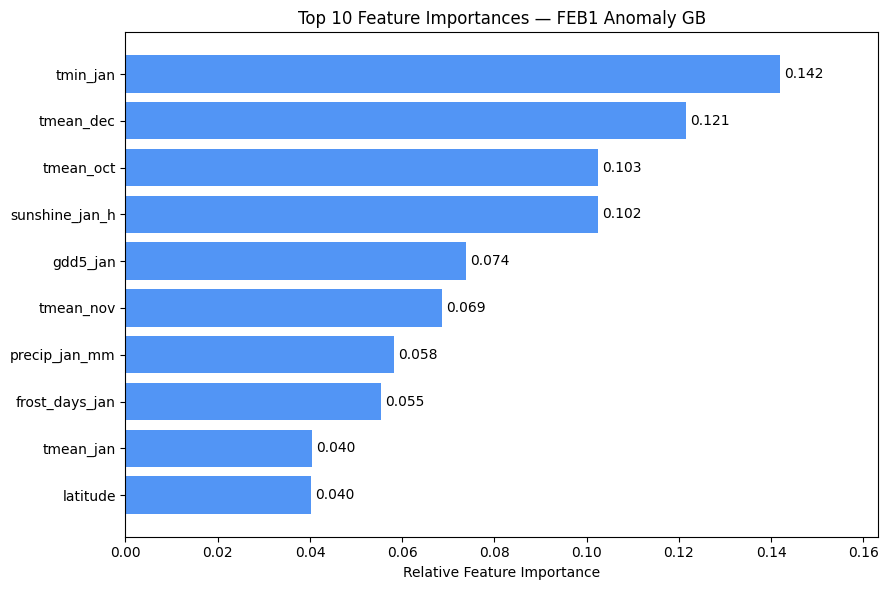

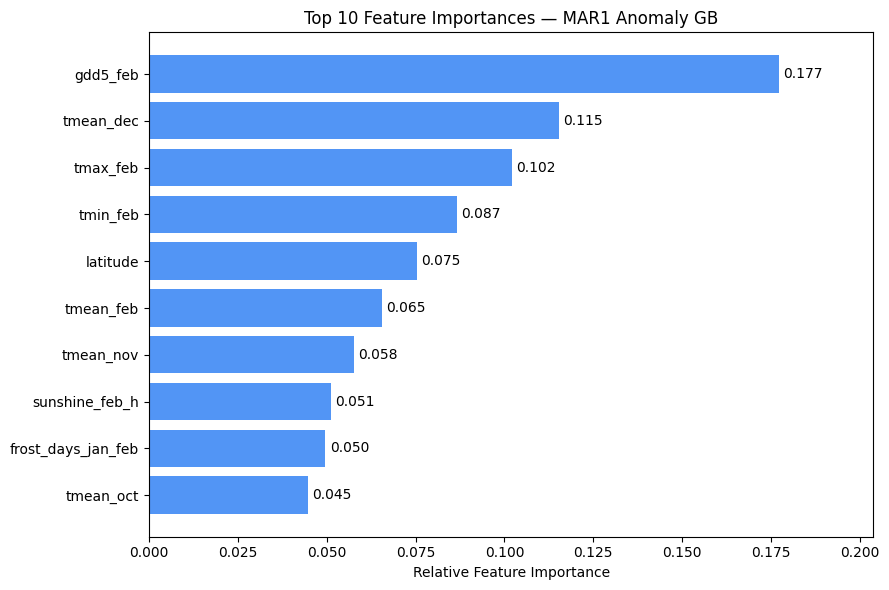

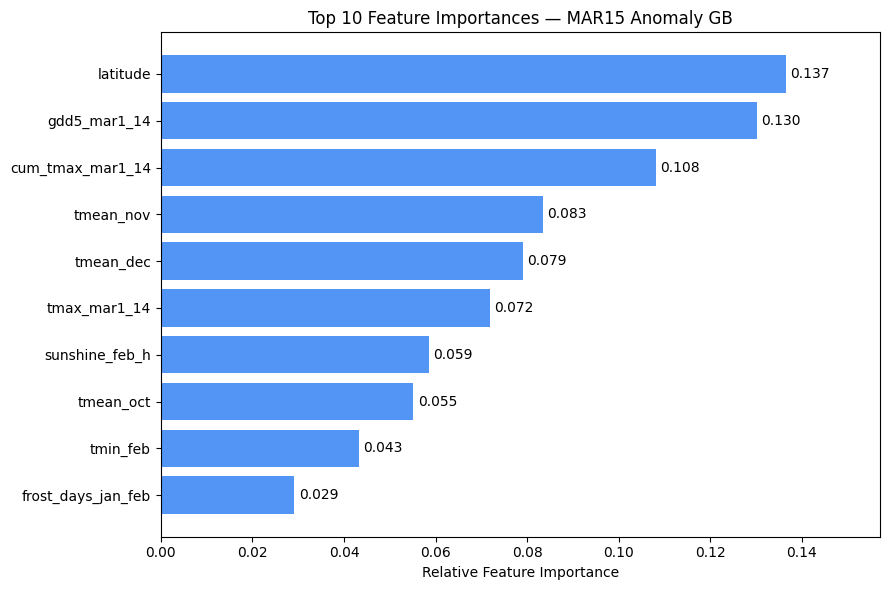

In [53]:
for date in forecast_dates:

    top = importance_results[date].head(10)
    top = top.sort_values("Importance")

    fig, ax = plt.subplots(figsize=(9, 6))

    bars = ax.barh(
        top["Feature"],
        top["Importance"],
        color="#5295F5"
    )

    ax.set_title(
        f"Top 10 Feature Importances — {date.upper()} Anomaly GB"
    )

    ax.set_xlabel("Relative Feature Importance")
    ax.bar_label(bars, fmt="%.3f", padding=3)

    ax.set_xlim(0, top["Importance"].max() * 1.15)

    plt.tight_layout()

    plt.savefig(
        output_dir / f"gb_{date}_feature_importance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

17. Final Model Comparison

In [54]:
final_rows = []

for date in forecast_dates:

    raw_mae = tuning_results[date].iloc[0]["MAE"]
    anomaly_mae = anomaly_tuning_results[date].iloc[0]["MAE"]

    best = best_anomaly_results[date].iloc[-1]

    final_rows.append({
        "Forecast Date": date,
        "Baseline MAE": 3.804,
        "Tuned Raw MAE": raw_mae,
        "Tuned Anomaly MAE": anomaly_mae,
        "Anomaly RMSE": best["RMSE"],
        "Anomaly R2": best["R2"],
        "Anomaly Hit Rate": best["hit_rate_3d"],
        "Improvement vs Baseline (%)":
            (3.804 - anomaly_mae) / 3.804 * 100
    })

final_comparison = pd.DataFrame(final_rows)

display(final_comparison.round(3))

,Forecast Date,Baseline MAE,Tuned Raw MAE,Tuned Anomaly MAE,Anomaly RMSE,Anomaly R2,Anomaly Hit Rate,Improvement vs Baseline (%)
0,feb1,3.804,3.846,3.783,4.540,0.816,0.473,0.558
1,mar1,3.804,3.799,3.644,4.381,0.822,0.504,4.216
2,mar15,3.804,3.054,3.034,3.738,0.875,0.575,20.246


18. Export All Results

In [55]:
# Save final comparison
final_comparison.to_csv(
    output_dir / "gb_final_comparison.csv",
    index=False
)

# Save fold 5 predictions and analysis
fold5_predictions.to_csv(
    output_dir / "gb_fold5_predictions.csv",
    index=False
)

year_analysis.to_csv(
    output_dir / "gb_fold5_year_analysis.csv",
    index=False
)

worst_stations.to_csv(
    output_dir / "gb_fold5_worst_predictions.csv",
    index=False
)

# Save feature importance for all dates
for date in forecast_dates:

    importance_results[date].to_csv(
        output_dir / f"gb_{date}_feature_importance.csv",
        index=False
    )

# Save best CV reports and tuning results
for date in forecast_dates:

    best_anomaly_results[date].to_csv(
        output_dir / f"gb_anomaly_{date}_cv.csv",
        index=False
    )

    anomaly_tuning_results[date].to_csv(
        output_dir / f"gb_anomaly_{date}_tuning.csv",
        index=False
    )

    tuning_results[date].to_csv(
        output_dir / f"gb_raw_{date}_tuning.csv",
        index=False
    )

print("All results exported successfully.")
print("Output folder:", output_dir.resolve())

All results exported successfully.
Output folder: /content/sakura_analytics/results/gradient_boosting


In [56]:
for file in sorted(output_dir.iterdir()):
    print(file.name)

gb_anomaly_feb1_cv.csv
gb_anomaly_feb1_tuning.csv
gb_anomaly_mar15_cv.csv
gb_anomaly_mar15_tuning.csv
gb_anomaly_mar1_cv.csv
gb_anomaly_mar1_tuning.csv
gb_anomaly_summary.csv
gb_feb1_feature_importance.csv
gb_feb1_feature_importance.png
gb_final_comparison.csv
gb_fold5_actual_vs_predicted.png
gb_fold5_error_distribution.png
gb_fold5_predictions.csv
gb_fold5_worst_predictions.csv
gb_fold5_year_analysis.csv
gb_mar15_feature_importance.csv
gb_mar15_feature_importance.png
gb_mar1_feature_importance.csv
gb_mar1_feature_importance.png
gb_model_comparison.csv
gb_model_comparison.png
gb_raw_feb1_tuning.csv
gb_raw_mar15_tuning.csv
gb_raw_mar1_tuning.csv


In [57]:
import shutil

shutil.make_archive(
    "gradient_boosting_results",
    "zip",
    root_dir="results",
    base_dir="gradient_boosting"
)

print("ZIP file created successfully.")

ZIP file created successfully.
